# Project Introduction  

In online shopping, users go through multiple steps — from viewing a product to adding it to the cart and finally making a purchase. At each step, some users leave, which affects overall sales.

The goal of this project is to study user behavior and find where and why users drop out of the funnel.

In this analysis, I will:
- Track how users move from one step to the next  
- Identify where most users drop  
- Understand what factors impact their decision to buy  

By the end, this will clearly show the problem areas and what can be improved to increase conversion.  

Home → Product Page → Cart → Checkout → Confirmation  



In [1]:
# Importing essential libraries for data analysis and visualization


import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.ticker import PercentFormatter

# scipy: used for statistical testing (chi-square test)
from scipy.stats import chi2_contingency

import warnings
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)


In [2]:
# Load dataset from a CSV file into a pandas DataFrame
df = pd.read_csv('customer_journey.csv')

# Confirm that the data has been loaded properly
print("Data loaded successfully!")

print("Shape:", df.shape)

# Complete list of column names
print("\nColumns:")
print("=" * 50)
print(df.columns.tolist())
print("=" * 50)

Data loaded successfully!
Shape: (12719, 10)

Columns:
['SessionID', 'UserID', 'Timestamp', 'PageType', 'DeviceType', 'Country', 'ReferralSource', 'TimeOnPage_seconds', 'ItemsInCart', 'Purchased']


In [3]:
# Count of missing (null) values for each column - beautifully formatted output
print("\n" + "="*60)
print("NULL VALUES SUMMARY")
print("="*60)
print(df.isnull().sum())
print("="*60)


NULL VALUES SUMMARY
SessionID             0
UserID                0
Timestamp             0
PageType              0
DeviceType            0
Country               0
ReferralSource        0
TimeOnPage_seconds    0
ItemsInCart           0
Purchased             0
dtype: int64


In [4]:
# Data types for each column with enhanced formatting
print("\n" + "="*60)
print("DATA TYPES SUMMARY")
print("="*60)
print(df.dtypes)
print("="*60)


DATA TYPES SUMMARY
SessionID             object
UserID                object
Timestamp             object
PageType              object
DeviceType            object
Country               object
ReferralSource        object
TimeOnPage_seconds     int64
ItemsInCart            int64
Purchased              int64
dtype: object


In [5]:
# Generate comprehensive summary statistics for numeric columns (mean, std, min, max, quartiles)
print("\n" + "="*60)
print("NUMERIC SUMMARY STATISTICS")
print("="*60)
print(df.describe())
print("="*60)


NUMERIC SUMMARY STATISTICS
       TimeOnPage_seconds   ItemsInCart     Purchased
count        12719.000000  12719.000000  12719.000000
mean            97.427707      1.138533      0.397044
std             48.120729      1.689954      0.489304
min             15.000000      0.000000      0.000000
25%             56.000000      0.000000      0.000000
50%             98.000000      0.000000      0.000000
75%            139.000000      2.000000      1.000000
max            180.000000      5.000000      1.000000


## Basic Data Insights  

A quick look at the numerical columns shows some initial patterns:

- Average time spent on page is around 97 seconds, which suggests users are engaging with the content.  
- Average items added to cart is close to 1, meaning most users add very few items.  
- Around 39% of sessions result in a purchase, giving us a baseline conversion rate.  



In [6]:
df.head()

,SessionID,UserID,Timestamp,PageType,DeviceType,Country,ReferralSource,TimeOnPage_seconds,ItemsInCart,Purchased
0,session_0,user_2223,2025-01-20 22:53:34,home,Desktop,India,Social Media,55,0,0
1,session_1,user_2192,2025-02-26 12:57:10,home,Tablet,Germany,Email,99,0,0
2,session_1,user_2192,2025-02-26 12:59:11,product_page,Tablet,Germany,Email,121,0,0
3,session_2,user_1708,2025-06-24 15:40:46,home,Mobile,India,Google,160,0,0
4,session_3,user_2976,2025-06-11 07:21:02,home,Tablet,UK,Google,113,0,0


In [7]:
df['PageType'].unique()

array(['home', 'product_page', 'cart', 'checkout', 'confirmation'],
      dtype=object)

In [8]:
# Funnel Step-by-Step Analysis

# Define the correct funnel order
funnel_stage = ['home', 'product_page', 'cart', 'checkout', 'confirmation']

# Count unique sessions reaching each funnel step
funnel_df = (df.groupby('PageType')['SessionID'].nunique().reindex(funnel_stage).reset_index())

funnel_df.columns = ['PageType','SessionCount']

# Calculate next step session count
funnel_df['NextStepSessionCount'] = funnel_df['SessionCount'].shift(-1)

# Calculate step-to-step conversion %
funnel_df['To_Next_Step_Conversion_%'] = (funnel_df['NextStepSessionCount'] / funnel_df['SessionCount']) * 100

# Calculate drop count
funnel_df['Drop_Count'] = funnel_df['SessionCount'] - funnel_df['NextStepSessionCount']

# Calculate drop %
funnel_df['Drop_%'] = (funnel_df['Drop_Count'] / funnel_df['SessionCount']) * 100

# Calculate overall conversion % from first step
first_step_sessions = funnel_df.loc[0, 'SessionCount']
funnel_df['Overall_Conversion_%'] = ( funnel_df['SessionCount'] / first_step_sessions) * 100

# Final step has no next step, so we keep it blank instead of 0
funnel_df.loc[funnel_df.index[-1], ['NextStepSessionCount', 'To_Next_Step_Conversion_%', 'Drop_Count', 'Drop_%']] = np.nan

print("Funnel Step-by-Step Analysis:")
print("\n" + "="*60)
display(funnel_df)
print("\n" + "="*60)

Funnel Step-by-Step Analysis:



,PageType,SessionCount,NextStepSessionCount,To_Next_Step_Conversion_%,Drop_Count,Drop_%,Overall_Conversion_%
0,home,5000,3987.0,79.740000,1013.0,20.260000,100.00
1,product_page,3987,1599.0,40.105342,2388.0,59.894658,79.74
2,cart,1599,1123.0,70.231395,476.0,29.768605,31.98
3,checkout,1123,1010.0,89.937667,113.0,10.062333,22.46
4,confirmation,1010,NaN,NaN,NaN,NaN,20.20


## Funnel Step-by-Step Analysis 

The funnel analysis shows how sessions move through each step from Home to Confirmation.

### Key Observation  

The biggest drop happens between the **Product Page** and **Cart** stage.

- Around **79.74%** of sessions reach the Product Page  
- But only **40.11%** continue to the Cart  
- This results in a drop of **59.89%**, which is the highest in the funnel  

### Behavior Pattern  

Once users add items to the cart, the conversion improves significantly:

- **70.23%** move from Cart to Checkout  
- **89.94%** move from Checkout to Confirmation  

This shows that users who reach the cart stage have strong purchase intent.

### Business Insight  

The main issue is not at the checkout stage but earlier in the funnel. The Product Page to Cart transition needs deeper analysis, as this is where most sessions drop.

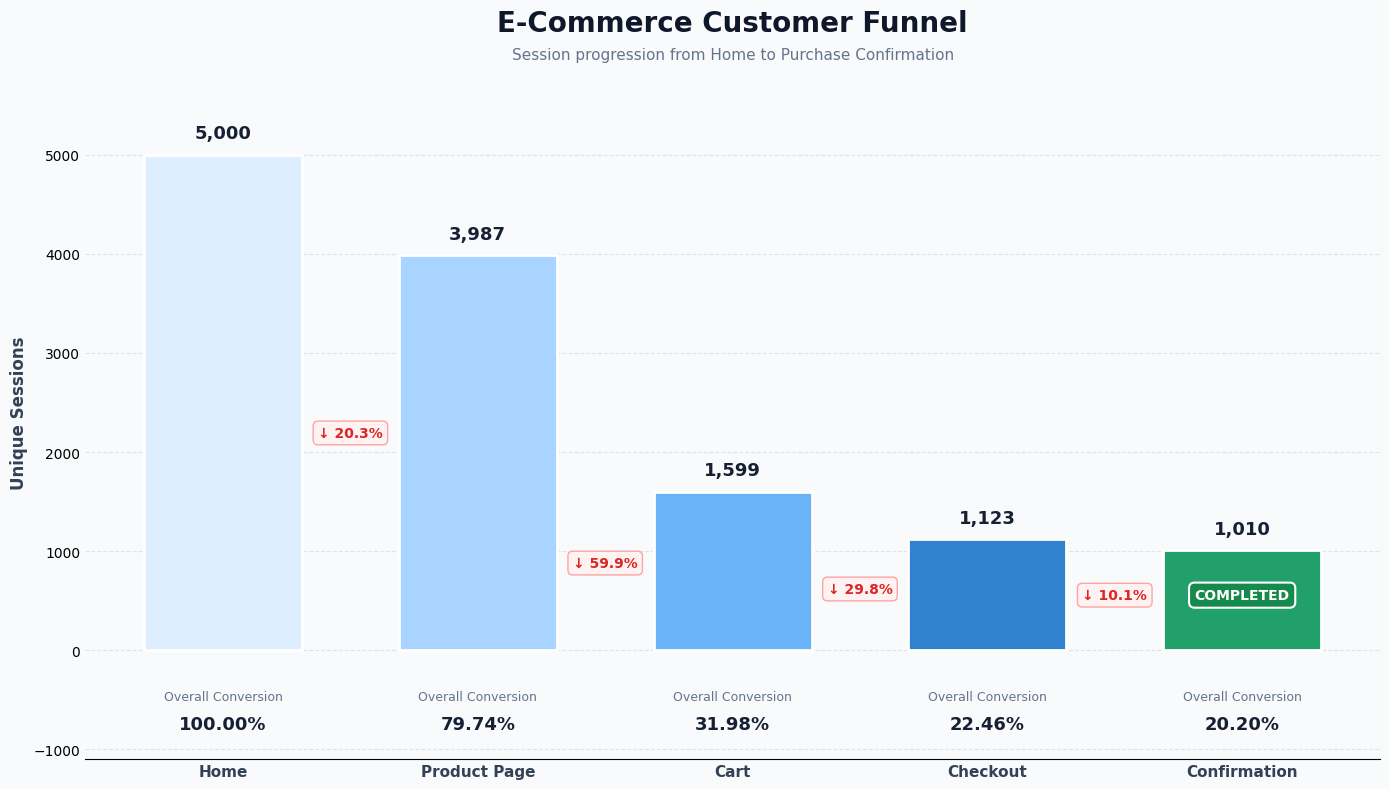

In [9]:
from matplotlib.colors import LinearSegmentedColormap

# =========================================================
# 1. Define funnel order
# =========================================================

funnel_steps = [
    'home',
    'product_page',
    'cart',
    'checkout',
    'confirmation'
]


# =========================================================
# 2. Create funnel dataframe
# =========================================================

funnel_df = (
    df.groupby('PageType')['SessionID']
      .nunique()
      .reindex(funnel_steps)
      .reset_index()
)

funnel_df.columns = [
    'PageType',
    'SessionCount'
]


# =========================================================
# 3. Calculate next-step sessions
# =========================================================

funnel_df['NextStepSessionCount'] = (
    funnel_df['SessionCount'].shift(-1)
)


# =========================================================
# 4. Calculate step-to-step conversion
# =========================================================

funnel_df['To_Next_Step_Conversion_%'] = (
    funnel_df['NextStepSessionCount']
    / funnel_df['SessionCount']
) * 100


# =========================================================
# 5. Calculate drop count
# =========================================================

funnel_df['Drop_Count'] = (
    funnel_df['SessionCount']
    - funnel_df['NextStepSessionCount']
)


# =========================================================
# 6. Calculate drop percentage
# =========================================================

funnel_df['Drop_%'] = (
    funnel_df['Drop_Count']
    / funnel_df['SessionCount']
) * 100


# =========================================================
# 7. Calculate overall conversion
# =========================================================

first_step_sessions = funnel_df.loc[0, 'SessionCount']

funnel_df['Overall_Conversion_%'] = (
    funnel_df['SessionCount']
    / first_step_sessions
) * 100


# =========================================================
# 8. Remove calculations for final stage
# =========================================================

funnel_df.loc[
    funnel_df.index[-1],
    [
        'NextStepSessionCount',
        'To_Next_Step_Conversion_%',
        'Drop_Count',
        'Drop_%'
    ]
] = np.nan


# =========================================================
# 9. Prepare chart data
# =========================================================

stages = funnel_df['PageType'].tolist()

session_counts = (
    funnel_df['SessionCount']
    .astype(float)
    .tolist()
)

overall_conversion = (
    funnel_df['Overall_Conversion_%']
    .astype(float)
    .tolist()
)

drop_percentages = (
    funnel_df['Drop_%']
    .astype(float)
    .tolist()
)

x = np.arange(len(stages))


# =========================================================
# 10. Create blue gradient
# =========================================================

blue_cmap = LinearSegmentedColormap.from_list(
    "blue_gradient",
    [
        "#DCEEFF",
        "#A9D4FF",
        "#69B3F8",
        "#3182CE",
        "#1E5AA8"
    ]
)

colors = [
    blue_cmap(i / (len(stages) - 1))
    for i in range(len(stages))
]

# Confirmation = green
colors[-1] = "#22A06B"


# =========================================================
# 11. Create figure
# =========================================================

fig, ax = plt.subplots(
    figsize=(14, 8)
)

fig.patch.set_facecolor("#F8FAFC")
ax.set_facecolor("#F8FAFC")


# =========================================================
# 12. Create bars
# =========================================================

bars = ax.bar(
    x,
    session_counts,
    width=0.62,
    color=colors,
    edgecolor="white",
    linewidth=2,
    zorder=3
)


# =========================================================
# 13. Session count above bars
# =========================================================

for bar, count in zip(
    bars,
    session_counts
):

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + max(session_counts) * 0.025,
        f"{int(count):,}",
        ha="center",
        va="bottom",
        fontsize=13,
        fontweight="bold",
        color="#172033"
    )


# =========================================================
# 14. Overall conversion below bars
# =========================================================

for i, conversion in enumerate(
    overall_conversion
):

    ax.text(
        x[i],
        -max(session_counts) * 0.08,
        "Overall Conversion",
        ha="center",
        va="top",
        fontsize=9,
        color="#64748B"
    )

    ax.text(
        x[i],
        -max(session_counts) * 0.13,
        f"{conversion:.2f}%",
        ha="center",
        va="top",
        fontsize=13,
        fontweight="bold",
        color="#172033"
    )


# =========================================================
# 15. Add drop-off percentages
# =========================================================

for i in range(len(stages) - 1):

    drop_pct = drop_percentages[i]

    current = session_counts[i]
    next_step = session_counts[i + 1]

    y_position = min(
        current,
        next_step
    ) * 0.55

    mid_x = (
        x[i] + x[i + 1]
    ) / 2

    ax.text(
        mid_x,
        y_position,
        f"↓ {drop_pct:.1f}%",
        ha="center",
        va="center",
        fontsize=10,
        fontweight="bold",
        color="#DC2626",
        bbox=dict(
            boxstyle="round,pad=0.35",
            facecolor="#FEF2F2",
            edgecolor="#FCA5A5",
            linewidth=1
        ),
        zorder=5
    )


# =========================================================
# 16. Highlight confirmation
# =========================================================

ax.text(
    x[-1],
    session_counts[-1] * 0.55,
    "COMPLETED",
    ha="center",
    va="center",
    fontsize=10,
    fontweight="bold",
    color="white",
    bbox=dict(
        boxstyle="round,pad=0.4",
        facecolor="#168A4A",
        edgecolor="white",
        linewidth=1.5
    ),
    zorder=5
)


# =========================================================
# 17. X-axis
# =========================================================

ax.set_xticks(x)

ax.set_xticklabels(
    [
        "Home",
        "Product Page",
        "Cart",
        "Checkout",
        "Confirmation"
    ],
    fontsize=11,
    fontweight="bold",
    color="#334155"
)


# =========================================================
# 18. Y-axis
# =========================================================

ax.set_ylabel(
    "Unique Sessions",
    fontsize=12,
    fontweight="bold",
    color="#334155"
)


# =========================================================
# 19. Title
# =========================================================

ax.set_title(
    "E-Commerce Customer Funnel",
    fontsize=20,
    fontweight="bold",
    color="#0F172A",
    pad=25
)

ax.text(
    0.5,
    1.01,
    "Session progression from Home to Purchase Confirmation",
    transform=ax.transAxes,
    ha="center",
    fontsize=11,
    color="#64748B"
)


# =========================================================
# 20. Grid
# =========================================================

ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.8,
    alpha=0.25,
    color="#94A3B8",
    zorder=0
)


# =========================================================
# 21. Remove unnecessary borders
# =========================================================

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.tick_params(
    axis="y",
    length=0
)

ax.tick_params(
    axis="x",
    length=0
)


# =========================================================
# 22. Space for conversion labels
# =========================================================

ax.set_ylim(
    -max(session_counts) * 0.22,
    max(session_counts) * 1.18
)


# =========================================================
# 23. Layout
# =========================================================

plt.tight_layout()

plt.show()

## Funnel Step-by-Step Analysis 

The funnel analysis shows how sessions move through each step from Home to Confirmation.

### Key Observation  

The biggest drop happens between the **Product Page** and **Cart** stage.

- Around **79.74%** of sessions reach the Product Page  
- But only **40.11%** continue to the Cart  
- This results in a drop of **59.89%**, which is the highest in the funnel  

### Behavior Pattern  

Once users add items to the cart, the conversion improves significantly:

- **70.23%** move from Cart to Checkout  
- **89.94%** move from Checkout to Confirmation  

This shows that users who reach the cart stage have strong purchase intent.

### Business Insight  

The main issue is not at the checkout stage but earlier in the funnel. The Product Page to Cart transition needs deeper analysis, as this is where most sessions drop.

In [10]:
# Device-wise Funnel Analysis

# Define funnel order
funnel_steps = ['home', 'product_page', 'cart', 'checkout', 'confirmation']

# Count unique sessions by DeviceType and PageType
device_funnel = (df.groupby(['DeviceType', 'PageType'])['SessionID'].nunique().reset_index(name='SessionCount'))

# Keep funnel steps in correct order
device_funnel['PageType'] = pd.Categorical(device_funnel['PageType'],categories=funnel_steps,ordered=True)

device_funnel = device_funnel.sort_values(['DeviceType', 'PageType'])

# Pivot to get stages as rows and devices as columns
device_funnel_pivot = (device_funnel.pivot(index='PageType', columns='DeviceType', values='SessionCount').reindex(funnel_steps))


# Step-to-step conversion by device
device_step_conversion = device_funnel_pivot.shift(-1) / device_funnel_pivot * 100

# Overall conversion from home by device
device_overall_conversion = device_funnel_pivot / device_funnel_pivot.loc['home'] * 100

# Drop count by device
device_drop_count = device_funnel_pivot - device_funnel_pivot.shift(-1)

# Drop % by device
device_drop_percent = device_drop_count / device_funnel_pivot * 100

# Final step has no next step, so keep it blank
device_step_conversion.loc['confirmation'] = np.nan
device_drop_count.loc['confirmation'] = np.nan
device_drop_percent.loc['confirmation'] = np.nan

print("Device-wise Funnel Session Counts:")
display(device_funnel_pivot)


print("Device-wise Step-to-Step Conversion (%):")
display(device_step_conversion.round(2))


print("Device-wise Drop Count:")
display(device_drop_count.round(0))


print("Device-wise Drop Percentage (%):")
display(device_drop_percent.round(2))


print("Device-wise Overall Conversion from Home (%):")
display(device_overall_conversion.round(2))

Device-wise Funnel Session Counts:


DeviceType,Desktop,Mobile,Tablet
PageType,,,
home,1666,1671,1663
product_page,1321,1342,1324
cart,529,537,533
checkout,385,369,369
confirmation,339,337,334


Device-wise Step-to-Step Conversion (%):


DeviceType,Desktop,Mobile,Tablet
PageType,,,
home,79.29,80.31,79.62
product_page,40.05,40.01,40.26
cart,72.78,68.72,69.23
checkout,88.05,91.33,90.51
confirmation,NaN,NaN,NaN


Device-wise Drop Count:


DeviceType,Desktop,Mobile,Tablet
PageType,,,
home,345.0,329.0,339.0
product_page,792.0,805.0,791.0
cart,144.0,168.0,164.0
checkout,46.0,32.0,35.0
confirmation,NaN,NaN,NaN


Device-wise Drop Percentage (%):


DeviceType,Desktop,Mobile,Tablet
PageType,,,
home,20.71,19.69,20.38
product_page,59.95,59.99,59.74
cart,27.22,31.28,30.77
checkout,11.95,8.67,9.49
confirmation,NaN,NaN,NaN


Device-wise Overall Conversion from Home (%):


DeviceType,Desktop,Mobile,Tablet
PageType,,,
home,100.00,100.00,100.00
product_page,79.29,80.31,79.62
cart,31.75,32.14,32.05
checkout,23.11,22.08,22.19
confirmation,20.35,20.17,20.08


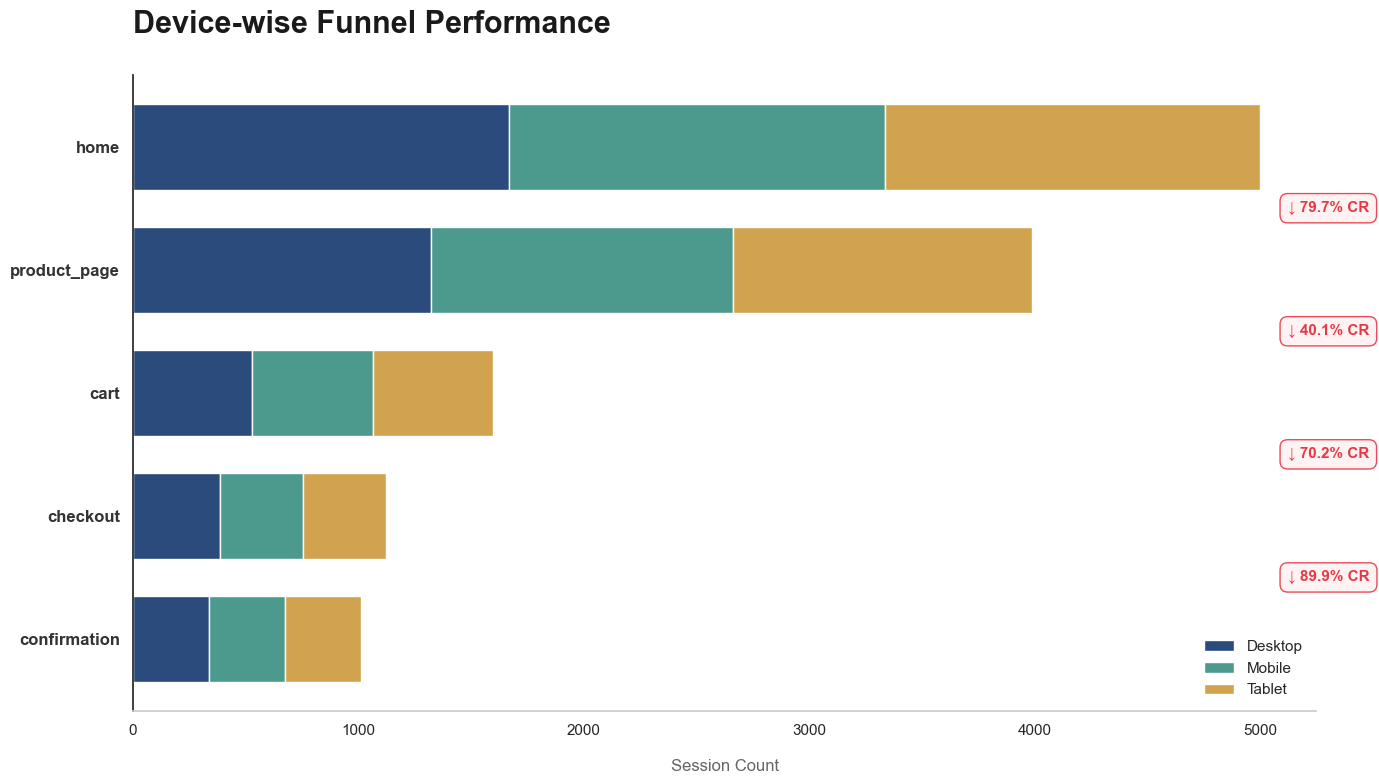

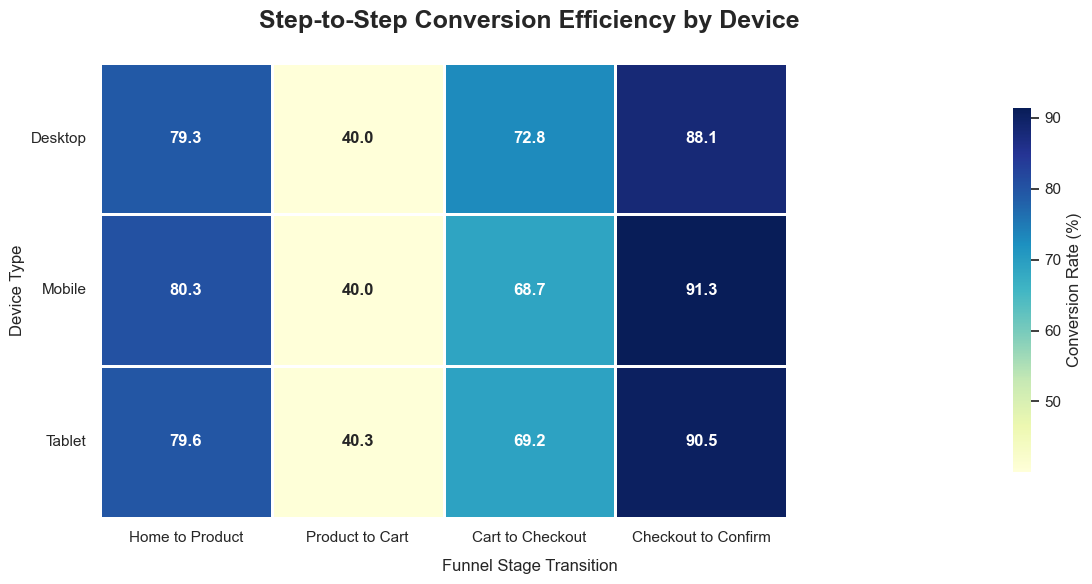

In [11]:
# Updated: Set theme with compatible font handling
sns.set_theme(style="white", rc={"font.family": "sans-serif"})

# Define a professional color palette
colors = {'Desktop': '#2A4B7C', 'Mobile': '#4C9A8E', 'Tablet': '#D1A34F'}

# ---------------------------------------------------------
# 1. Stacked Horizontal Funnel Bars (Sessions)
# ---------------------------------------------------------
fig, ax = plt.subplots(figsize=(14, 8))

# Data Setup (assuming device_funnel_pivot and funnel_steps are defined)
y_pos = np.arange(len(funnel_steps))
bottom = np.zeros(len(funnel_steps))
total_widths = device_funnel_pivot.sum(axis=1).values

# Plotting Bars
for device in device_funnel_pivot.columns:
    vals = device_funnel_pivot[device].values
    ax.barh(y_pos, vals, left=bottom, label=device, 
            color=colors.get(device, '#808080'), height=0.7, 
            edgecolor='white', linewidth=1)
    bottom += vals

# Styling Axes
ax.set_yticks(y_pos)
ax.set_yticklabels(funnel_steps, fontsize=12, fontweight='bold', color='#333333')
ax.invert_yaxis()  # Logical funnel flow: Top to Bottom
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_color('#CCCCCC')
ax.set_xlabel('Session Count', fontsize=12, labelpad=15, color='#666666')

# Conversion labels (Right-side badges)
max_val = total_widths.max()
for i in range(len(funnel_steps)-1):
    total_curr = total_widths[i]
    total_next = total_widths[i+1]
    conv = (total_next / total_curr) * 100
    
    # Placing conversion rate badge between the steps
    ax.annotate(f'↓ {conv:.1f}% CR', 
                xy=(max_val, i + 0.5), 
                xytext=(20, 0), textcoords='offset points',
                ha='left', va='center', fontsize=11, fontweight='bold',
                color='#E63946', 
                bbox=dict(boxstyle='round,pad=0.5', fc='#FFF1F1', ec='#E63946', alpha=0.9))

# Title and Legend
plt.title('Device-wise Funnel Performance', fontsize=22, fontweight='bold', 
          pad=30, loc='left', color='#1A1A1A')
ax.legend(frameon=False, loc='lower right', fontsize=11)

plt.tight_layout()

# Save and Show
plt.savefig('02_device_funnel.png', dpi=300, bbox_inches='tight')
plt.show()


# ---------------------------------------------------------
# 2. Step Conversion Heatmap (Seaborn)
# ---------------------------------------------------------
plt.figure(figsize=(12, 6))
# Create specific labels for the transitions
transition_labels = ['Home to Product', 'Product to Cart', 'Cart to Checkout', 'Checkout to Confirm']

# Plotting Heatmap with spacing and modern color ramp
ax = sns.heatmap(device_step_conversion.T,
                 xticklabels=transition_labels,
                 annot=True, 
                 fmt='.1f', 
                 cmap='YlGnBu', 
                 linewidths=2, 
                 cbar_kws={'label': 'Conversion Rate (%)', 'shrink': .8},
                 annot_kws={"size": 12, "weight": "bold"})

# Formatting
plt.title('Step-to-Step Conversion Efficiency by Device', fontsize=18, 
          fontweight='bold', pad=25, loc='center')
plt.xlabel('Funnel Stage Transition', fontsize=12, labelpad=10)
plt.ylabel('Device Type', fontsize=12)

# Clean up tick rotation
plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.tight_layout()

# Save and Show
plt.savefig('03_device_conversions_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

## Device-wise Funnel Analysis  

Checked if devices perform differently in the funnel. They don't.

All three — Desktop, Mobile, Tablet — show nearly the same conversion at every step. The drop pattern is identical across devices. The chi-square test in the next cell confirms this statistically.

So the problem is not device-specific. Fixing mobile UX or desktop layout alone won't help — the issue is on the Product Page itself, regardless of what device people use.

In [12]:
session_device = df.groupby('SessionID').agg(
    Device=('DeviceType','first'),
    Purchased=('Purchased','max')).reset_index()


#Device × Purchase status
contingency_table =  pd.crosstab(session_device['Device'],session_device['Purchased'])

chi2, p_value, dof, expected = chi2_contingency(contingency_table)

print("Chi-Square Test: Device Type vs Conversion")
print(f"Chi-Square Statistic: {chi2:.4f}")
print(f"P-Value: {p_value:.4f}")
print(f"Degrees of Freedom: {dof}")

if p_value < 0.05:
    print("\nResult: Statistically significant difference exists between devices.")
else:
    print("\nResult: No statistically significant difference between devices.")

Chi-Square Test: Device Type vs Conversion
Chi-Square Statistic: 0.0376
P-Value: 0.9814
Degrees of Freedom: 2

Result: No statistically significant difference between devices.


We tested whether device type is associated with purchase conversion. The Chi-Square test returned a p-value of approximately 0.981, which is much higher than the 0.05 significance threshold. Therefore, we found no statistically significant association between device type and conversion. Desktop, Mobile, and Tablet users have broadly similar conversion behavior, so device type is unlikely to be the primary driver of the funnel bottleneck.

In [13]:
# Time Spent in Funnel (Session Duration Analysis)

df['Timestamp'] = pd.to_datetime(df['Timestamp'])

# Step 1: Calculate session-level start time, end time, and total duration
session_time = (df.groupby('SessionID')['Timestamp'].agg(SessionStart='min', SessionEnd='max').reset_index())

session_time['SessionDuration_seconds'] = (session_time['SessionEnd'] - session_time['SessionStart']).dt.total_seconds()

# Step 2: Create session-level purchase flag
# If any row in a session has Purchased = 1, mark the whole session as converted
session_purchase = ( df.groupby('SessionID')['Purchased'].max().reset_index().rename(columns={'Purchased': 'SessionPurchased'}))

# Step 3: Merge session duration with session purchase flag
session_summary = pd.merge(session_time, session_purchase, on='SessionID', how='left')

# Step 4: Get average time to confirmation for converted sessions only
avg_time_to_conv = (session_summary.loc[session_summary['SessionPurchased'] == 1, 'SessionDuration_seconds'].mean())

print(f"Average Time from First Page to Confirmation (for converters): {avg_time_to_conv:.2f} seconds")

# Step 5: Compare average session duration for converted vs non-converted sessions
avg_duration_comparison = (session_summary.groupby('SessionPurchased')['SessionDuration_seconds'].mean().reset_index())

# Optional: rename values for readability
avg_duration_comparison['SessionPurchased'] = avg_duration_comparison['SessionPurchased'].map({
    0: 'No Purchase',
    1: 'Purchase'})

print("\nAverage Session Duration Comparison:")
display(avg_duration_comparison)

# Optional: extra summary for deeper understanding
duration_summary = (session_summary.groupby('SessionPurchased')['SessionDuration_seconds'].agg(['count', 'mean', 'median', 'min', 'max']).reset_index())

duration_summary['SessionPurchased'] = duration_summary['SessionPurchased'].map({
    0: 'No Purchase',
    1: 'Purchase'})

print("\nSession Duration Summary:")
display(duration_summary)

Average Time from First Page to Confirmation (for converters): 388.24 seconds

Average Session Duration Comparison:


,SessionPurchased,SessionDuration_seconds
0,No Purchase,89.751629
1,Purchase,388.237624



Session Duration Summary:


,SessionPurchased,count,mean,median,min,max
0,No Purchase,3990,89.751629,81.0,0.0,468.0
1,Purchase,1010,388.237624,389.0,117.0,668.0


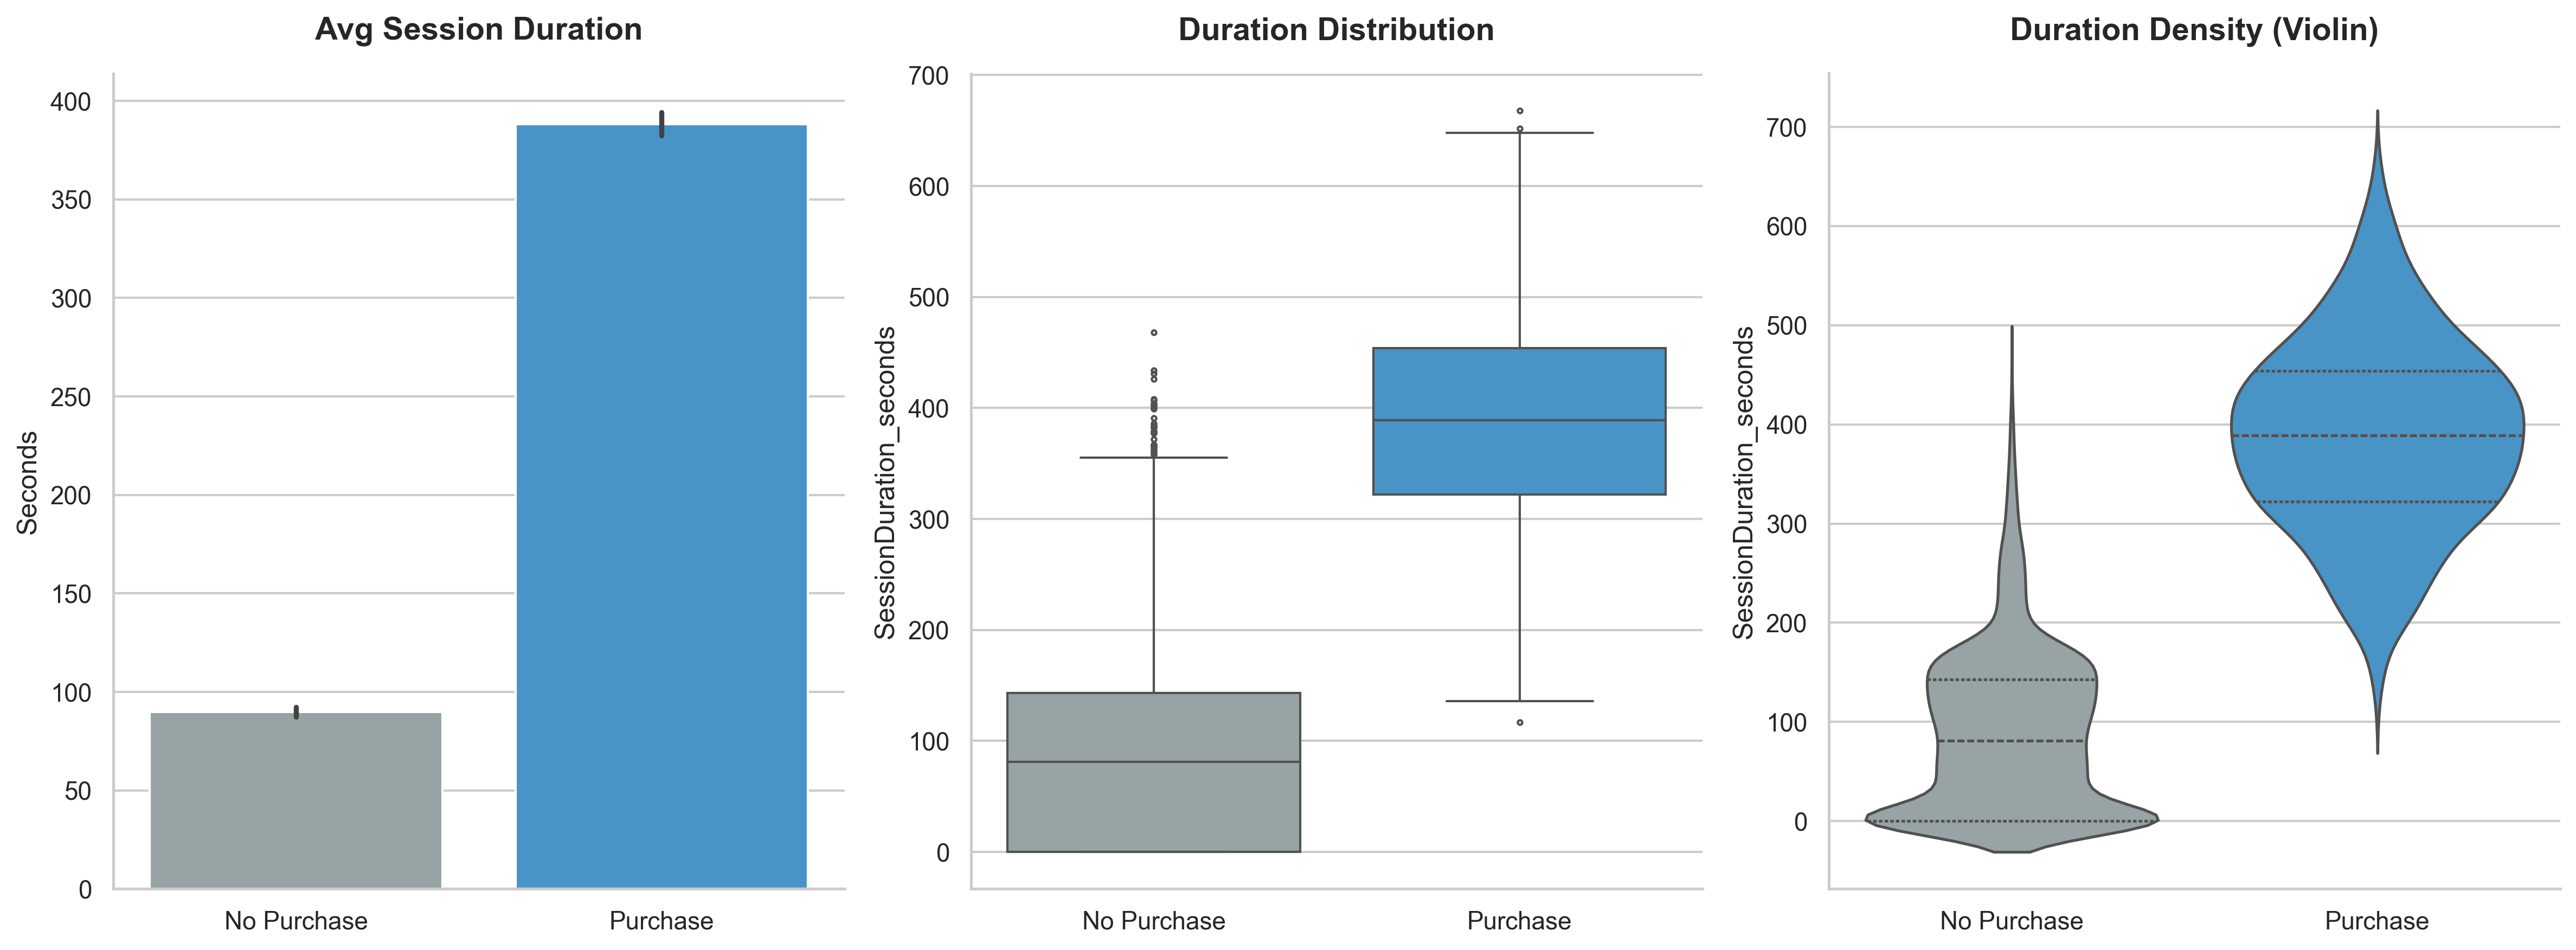

In [14]:
sns.set_theme(style="whitegrid", palette="muted")
labels = ['No Purchase', 'Purchase']
colors = ["#95a5a6", "#3498db"] 

# Create the figure
fig, ax = plt.subplots(1, 3, figsize=(16, 6), dpi=300)

# 1. Bar Plot
sns.barplot(
    data=session_summary, 
    x='SessionPurchased', 
    y='SessionDuration_seconds', 
    ax=ax[0], 
    palette=colors,
    hue='SessionPurchased'
)
ax[0].set_title('Avg Session Duration', fontsize=14, fontweight='bold', pad=15)
ax[0].set_ylabel('Seconds', fontsize=12)

# 2. Box Plot
sns.boxplot(
    data=session_summary, 
    x='SessionPurchased', 
    y='SessionDuration_seconds', 
    ax=ax[1], 
    palette=colors,
    hue='SessionPurchased',
    fliersize=2
)
ax[1].set_title('Duration Distribution', fontsize=14, fontweight='bold', pad=15)

# 3. Violin Plot
sns.violinplot(
    data=session_summary, 
    x='SessionPurchased', 
    y='SessionDuration_seconds', 
    ax=ax[2], 
    palette=colors,
    hue='SessionPurchased',
    inner="quart"
)
ax[2].set_title('Duration Density (Violin)', fontsize=14, fontweight='bold', pad=15)

# General Cleanup for all subplots
for a in ax:
    a.set_xticklabels(labels)
    a.set_xlabel('') 
    
    leg = a.get_legend()
    if leg:
        leg.remove()
        
    sns.despine(ax=a)

plt.tight_layout()

# --- HIGH-END EXPORT CODE ---
# PNG is great for slides/docs; PDF/SVG is best for infinite scaling (vector)
fig.savefig("04_session_analysis_highres.png", dpi=300, bbox_inches='tight')
# fig.savefig("session_analysis_vector.svg", bbox_inches='tight') 

plt.show()

## Session Duration Insight  

Non-buyers spend about 90 seconds on the site. Buyers spend around 388 seconds — over 4x longer.

This makes sense. Buyers go through more steps (product → cart → checkout → confirmation), so they naturally spend more time. Non-buyers leave early, mostly after the product page.

This supports the funnel finding — users are dropping before they get deep enough into the journey.

In [15]:
# Product Page Time Analysis (Corrected)

# Create session-level purchase flag
session_purchase = df.groupby('SessionID')['Purchased'].max().reset_index()

# Merge back
df_merged = df.merge(session_purchase, on='SessionID', suffixes=('', '_Session'))

# Filter only product page
product_page_df = df_merged[df_merged['PageType'] == 'product_page']

# Aggregate
product_time_summary = product_page_df.groupby('Purchased_Session')['TimeOnPage_seconds'].agg(
    avg_time='mean',
    median_time='median',
    count='count'
).reset_index()

# Rename
product_time_summary['Purchased_Session'] = product_time_summary['Purchased_Session'].map({
    0: 'Non-Buyer',
    1: 'Buyer'
})

print("Product Page Time Analysis:")
display(product_time_summary)

Product Page Time Analysis:


,Purchased_Session,avg_time,median_time,count
0,Non-Buyer,97.427612,99.0,2977
1,Buyer,95.965347,96.5,1010


## Product Page Time — Buyers vs Non-Buyers  

This one was interesting. I expected buyers to spend more time on the product page than non-buyers. But they don't.

Both groups spend roughly the same time — around 96–97 seconds. So the product page is getting attention from everyone, but something on that page is not convincing enough to make people add to cart.

The problem isn't engagement. People are looking. They're just not acting.

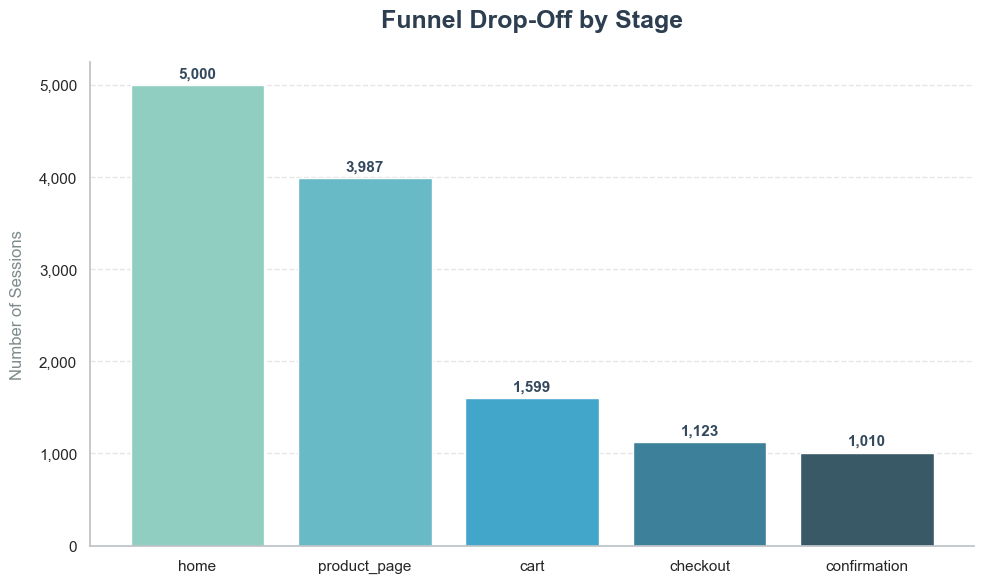

In [16]:
# 1. Theme & Color Palette
sns.set_theme(style="white")  # Clean white background
# Using a custom gradient from light grey to a strong corporate blue/teal
colors = sns.color_palette("GnBu_d", len(funnel_df)) 

# 2. Setup Figure and Axis
fig, ax = plt.subplots(figsize=(10, 6), dpi=100)

# 3. Create Bar Chart
bars = ax.bar(
    funnel_df['PageType'], 
    funnel_df['SessionCount'], 
    color=colors,
    width=0.8
)

# 4. Title and Labels
ax.set_title("Funnel Drop-Off by Stage", fontsize=18, fontweight='bold', pad=25, loc='center', color='#2c3e50')
ax.set_ylabel("Number of Sessions", fontsize=12, color='#7f8c8d', labelpad=10)

# 5. Add Value Labels on top of bars
for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width()/2.,
        height + (funnel_df['SessionCount'].max() * 0.01),
        f'{int(height):,}',
        ha='center', va='bottom', 
        fontsize=11, fontweight='bold', color='#34495e'
    )

# 6. Formatting & Cleanup
# Fixes the NameError by using mtick
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))

# Modernize the "look" by removing unnecessary lines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#bdc3c7')
ax.spines['bottom'].set_color('#bdc3c7')

# Add subtle horizontal gridlines
ax.yaxis.grid(True, linestyle='--', which='major', color='grey', alpha=.2)

# Adjust layout
plt.tight_layout()

# 7. High-End Export
# 300 DPI is the standard for high-quality print/presentations
fig.savefig('05_funnel_analysis_premium.png', dpi=300, bbox_inches='tight', transparent=False)

plt.show()

## Funnel Drop-Off Chart  

The bar chart above makes it pretty obvious — the session count drops sharply after the Product Page. The other steps lose some users too, but nothing close to that first big drop.

In [17]:
# Items in Cart Analysis (Session Level)

# Step 1: Get max items in cart per session
session_items = (df.groupby('SessionID')['ItemsInCart'].max().reset_index().rename(columns={'ItemsInCart':'MaxItemsInCart'}))

# Step 2: Get session-level purchase flag
session_purchase = (df.groupby('SessionID')['Purchased'].max().reset_index().rename(columns={'Purchased':'SessionPurchased'}))

# Step 3: Merge
items_summary = pd.merge(session_items,session_purchase, on='SessionID')

# Step 4: Calculate conversion rate
items_conv = (items_summary.groupby('MaxItemsInCart')['SessionPurchased'].mean().reset_index())

print("Conversion Rate by Items in Cart (Session Level):")
display(items_conv)

Conversion Rate by Items in Cart (Session Level):


,MaxItemsInCart,SessionPurchased
0,0,0.000000
1,1,0.376761
2,2,0.346221
3,3,0.381737
4,4,0.311943
5,5,0.309524


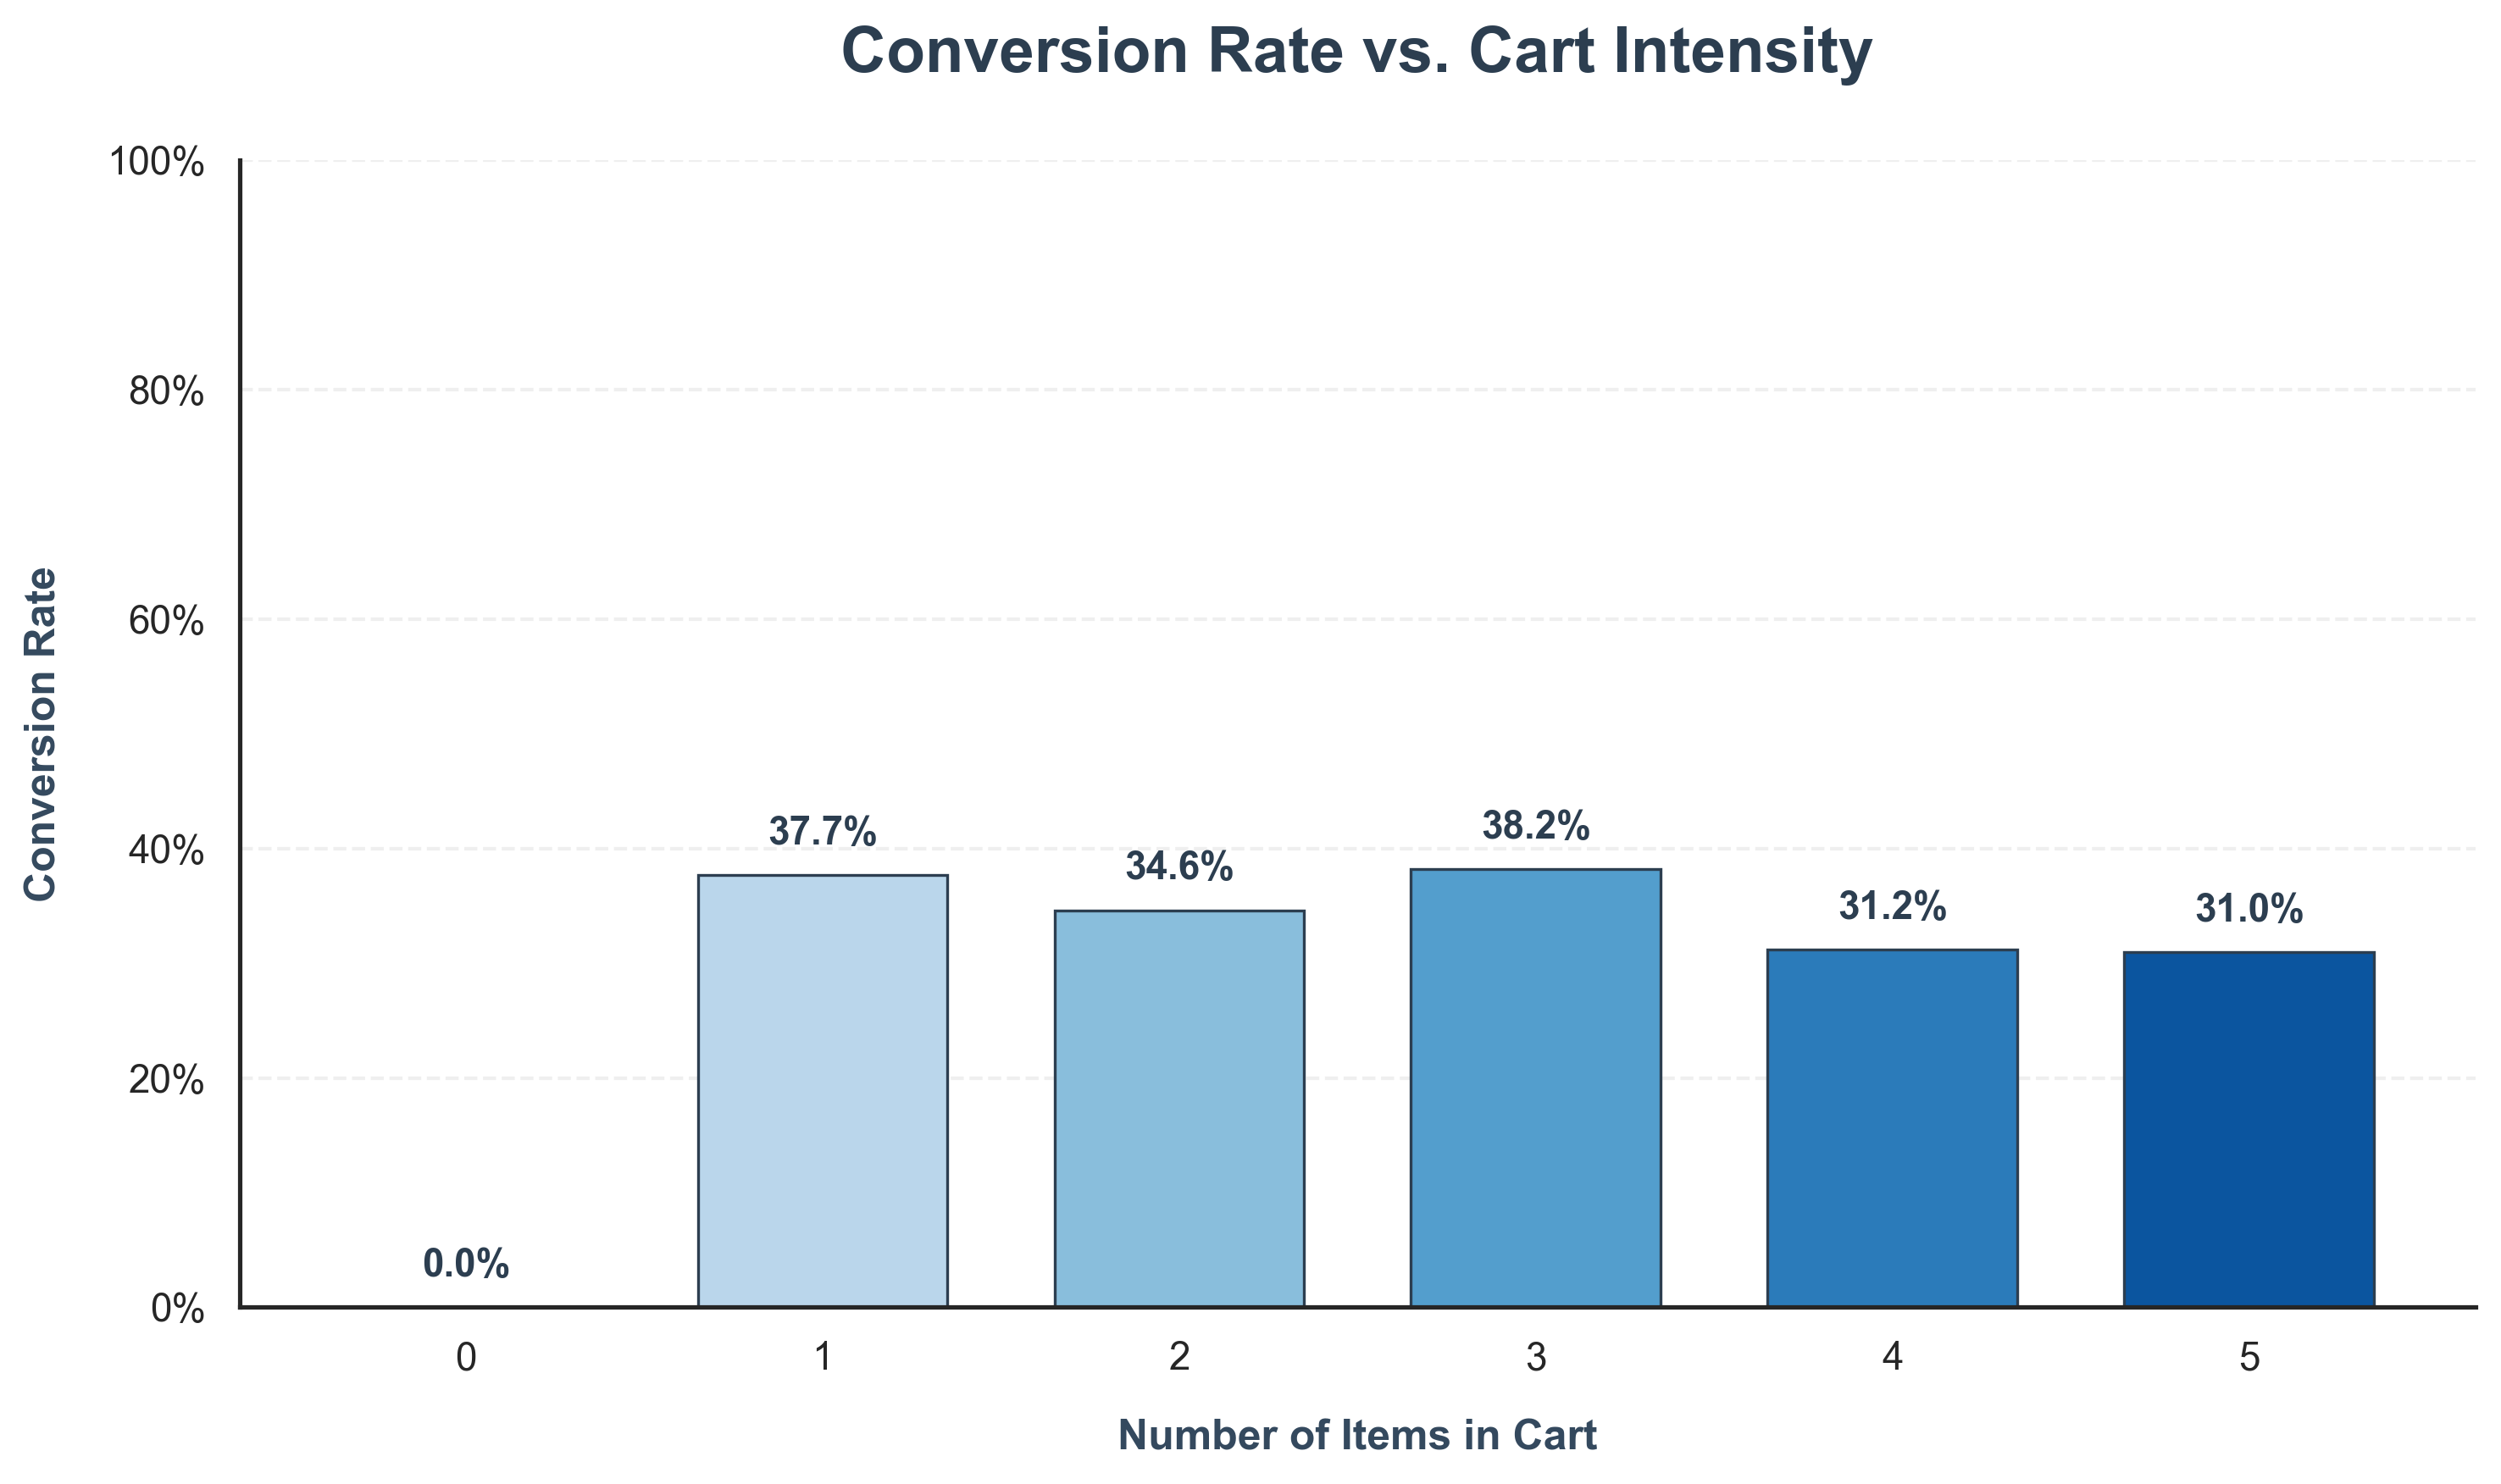

In [18]:
# 1. Setup Data & Aesthetics
# Assuming items_conv is your DataFrame
sns.set_theme(style="white")
# Creating a gradient palette based on the conversion values
colors = sns.color_palette("Blues", len(items_conv))

# 2. Create Figure and Axis
fig, ax = plt.subplots(figsize=(10, 6), dpi=300)

# 3. Create Bar Plot
bars = ax.bar(
    items_conv['MaxItemsInCart'], 
    items_conv['SessionPurchased'], 
    color=colors,
    edgecolor='#2c3e50',
    linewidth=0.8,
    width=0.7
)

# 4. Titles and Labels
ax.set_title('Conversion Rate vs. Cart Intensity', fontsize=18, fontweight='bold', pad=25, loc='Center', color='#2c3e50')
ax.set_xlabel('Number of Items in Cart', fontsize=12, fontweight='bold', labelpad=12, color='#34495e')
ax.set_ylabel('Conversion Rate', fontsize=12, fontweight='bold', labelpad=12, color='#34495e')

# 5. Formatting Y-Axis as percentage
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))

# 6. Add Percentage Labels on top of bars
for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width()/2., 
        height + 0.02, 
        f'{height:.1%}', 
        ha='center', 
        va='bottom', 
        fontsize=11, 
        fontweight='bold',
        color='#2c3e50'
    )

# 7. Final Polish
# Remove top and right spines
sns.despine(ax=ax)

# Add subtle horizontal gridlines for readability
ax.yaxis.grid(True, linestyle='--', alpha=0.3)

# Ensure X-axis shows all integer ticks (avoiding 0.5, 1.5, etc.)
ax.set_xticks(items_conv['MaxItemsInCart'])

# 8. High-End Export
plt.tight_layout()
fig.savefig("06_conversion_rate_analysis.png", dpi=300, bbox_inches='tight')
plt.show()

In [19]:
# Calculate session-level conversion by referral source
ref_conv =  df.groupby('ReferralSource')['Purchased'].mean().reset_index().sort_values(by='Purchased',ascending=False)

# Display clean table
print("Conversion Rate by Referral Source:")
display(round(ref_conv,2))

Conversion Rate by Referral Source:


,ReferralSource,Purchased
2,Google,0.42
0,Direct,0.39
1,Email,0.39
3,Social Media,0.38


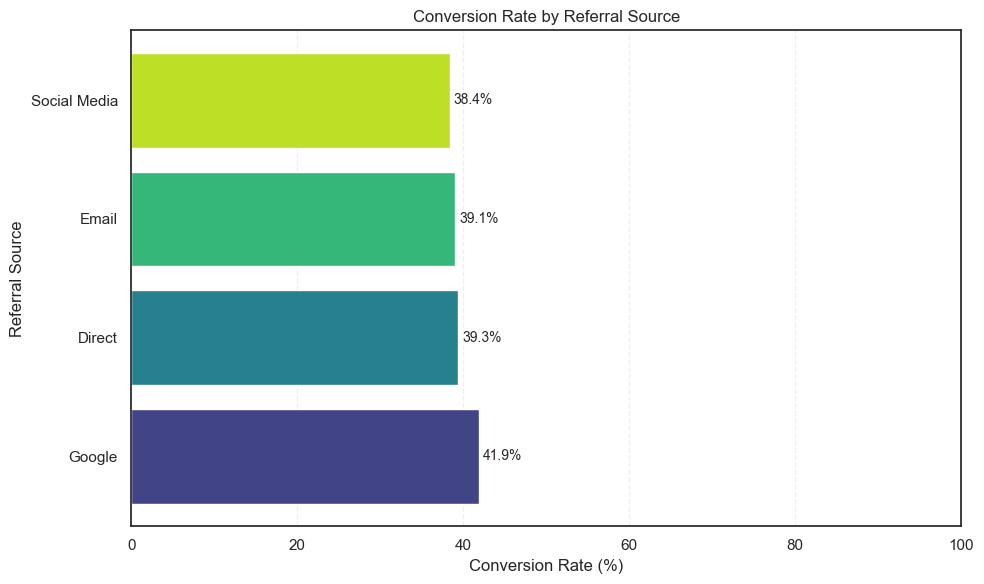

Conversion Rate by Referral Source:


,ReferralSource,Conversion Rate (%)
2,Google,41.918886
0,Direct,39.345855
1,Email,39.072229
3,Social Media,38.362761


In [20]:
# Convert to percentage
ref_conv['ConversionRate_%'] = ref_conv['Purchased'] * 100

# Create different color for each referral source
colors = plt.cm.viridis(
    np.linspace(0.2, 0.9, len(ref_conv))
)

# Plot
plt.figure(figsize=(10, 6))

bars = plt.barh(
    ref_conv['ReferralSource'],
    ref_conv['ConversionRate_%'],
    color=colors
)

# Add percentage labels
for bar, value in zip(bars, ref_conv['ConversionRate_%']):
    plt.text(
        bar.get_width() + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f'{value:.1f}%',
        va='center',
        fontsize=10
    )

plt.xlabel('Conversion Rate (%)')
plt.ylabel('Referral Source')
plt.title('Conversion Rate by Referral Source')
plt.xlim(0, 100)
plt.grid(axis='x', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

# Clean table
print("Conversion Rate by Referral Source:")
display(
    ref_conv[['ReferralSource', 'ConversionRate_%']]
    .rename(columns={'ConversionRate_%': 'Conversion Rate (%)'})
)

## Conversion by Referral Source  

Google converts slightly better (42%) than Social Media (38%), but the gap is small. Direct and Email sit in between. Nothing dramatic here.

In [21]:
# Step-to-Step Conversion by Referral Source ---

# Group by ReferralSource and PageType, count unique sessions
ref_segmented_counts  = df.groupby(['ReferralSource','PageType'])['SessionID'].nunique().unstack(level=0)

# Reorder the index (PageType) to follow the defined funnel steps
ref_segmented_counts = ref_segmented_counts.reindex(funnel_steps)

# Calculate step-to-step conversion percentage FOR EACH source separately
direct_conv  = (ref_segmented_counts['Direct'].shift(-1) / ref_segmented_counts['Direct']) * 100
email_conv = (ref_segmented_counts['Email'].shift(-1)/ ref_segmented_counts['Email']) * 100
google_conv  = (ref_segmented_counts['Google'].shift(-1) / ref_segmented_counts['Google']) * 100
social_conv  = (ref_segmented_counts['Social Media'].shift(-1) / ref_segmented_counts['Social Media']) * 100


ref_conversion = (
    ref_segmented_counts.shift(-1)
    .div(ref_segmented_counts)
    .mul(100)
    .iloc[:-1]
).reset_index()

ref_conversion.index = [
    'Home → Product Page',
    'Product Page → Cart',
    'Cart → Checkout',
    'Checkout → Confirmation'
]

display(ref_conversion.round(2))

ReferralSource,PageType,Direct,Email,Google,Social Media
Home → Product Page,home,78.79,81.53,79.22,79.40
Product Page → Cart,product_page,39.96,40.00,42.11,38.30
Cart → Checkout,cart,69.17,69.12,71.66,70.90
Checkout → Confirmation,checkout,91.01,89.01,90.52,89.18


## Step-to-Step Conversion by Referral Source  

Broke the funnel down by each referral channel to see if any source behaves differently at specific steps. They don't. Every source shows the same pattern — strong Home to Product, big drop at Product to Cart, strong recovery after Cart.

Google is slightly better at getting users into the cart, Social Media slightly worse, but the difference is too small to act on. The problem is the same across all channels.

In [22]:
# Statistical Test: Does referral source affect conversion?
session_ref = df.groupby('SessionID').agg(Source=('ReferralSource','first'),Purchased=('Purchased','max')).reset_index()

contingency_ref =  pd.crosstab(session_ref['Source'],session_ref['Purchased'])

chi2,  p_value , dof , exected = chi2_contingency(contingency_ref)

print("Chi-Square Test: Referral Source vs Conversion")
print(f"Chi-Square Statistic: {chi2:.4f}")
print(f"P-Value: {p_value:.4f}")
print(f"Degrees of Freedom: {dof}")

if p_value < 0.05:
    print("\nResult: Statistically significant difference exists between referral sources.")
else:
    print("\nResult: No statistically significant difference between referral sources.")

Chi-Square Test: Referral Source vs Conversion
Chi-Square Statistic: 2.5009
P-Value: 0.4751
Degrees of Freedom: 3

Result: No statistically significant difference between referral sources.


## Statistical Check — Referral Source vs Conversion  

Ran the same chi-square test for referral sources. P-value is 0.47 — not significant. Google, Email, Direct, Social Media — none of them convert meaningfully better than the others.

In [23]:
# Cart Abandonment Segmentation

# Step 1: Find sessions that reached the cart
cart_sessions = df.loc[df['PageType'] == 'cart','SessionID'].unique()

# Step 2: Create session-level purchase flag
session_purchase = (df.groupby('SessionID')['Purchased'].max().reset_index())

# Step 3: Keep only sessions that reached cart, then find non-purchasers
cart_sessions_df =  pd.DataFrame({'SessionID':cart_sessions})

cart_with_purchase  =  cart_sessions_df.merge(session_purchase,on='SessionID',how='left')

abandoned_cart_sessions  =  cart_with_purchase.loc[cart_with_purchase['Purchased'] == 0, 'SessionID']

# Step 4: Count abandoned cart sessions
print(f"Number of sessions that abandoned the cart: {len(abandoned_cart_sessions)}")

# Step 5: Check device distribution for abandoned cart sessions
abandoned_device_dist = (
    df[df['SessionID'].isin(abandoned_cart_sessions)]
    .drop_duplicates('SessionID')[['SessionID', 'DeviceType']]
    ['DeviceType']
    .value_counts(normalize=True)
    .reset_index()
)

abandoned_device_dist.columns = ['DeviceType', 'Percentage']

print("\nDevice Distribution for Cart Abandonment:")
display(abandoned_device_dist)

Number of sessions that abandoned the cart: 589

Device Distribution for Cart Abandonment:


,DeviceType,Percentage
0,Mobile,0.339559
1,Tablet,0.337861
2,Desktop,0.322581


## Cart Abandonment  

589 sessions made it to the cart but didn't buy. Checked if any device type was worse — nope. Desktop, Mobile, Tablet all abandon at roughly equal rates (~33% each).

Some users do drop after the cart, but it's a much smaller problem than the Product Page → Cart drop. Checkout improvements can help a bit, but the big win is still earlier in the funnel.


---

In [24]:
df['HourOfDay'] = df['Timestamp'].dt.hour
df['DayOfWeek'] = df['Timestamp'].dt.weekday
df.head(5)

,SessionID,UserID,Timestamp,PageType,DeviceType,Country,ReferralSource,TimeOnPage_seconds,ItemsInCart,Purchased,HourOfDay,DayOfWeek
0,session_0,user_2223,2025-01-20 22:53:34,home,Desktop,India,Social Media,55,0,0,22,0
1,session_1,user_2192,2025-02-26 12:57:10,home,Tablet,Germany,Email,99,0,0,12,2
2,session_1,user_2192,2025-02-26 12:59:11,product_page,Tablet,Germany,Email,121,0,0,12,2
3,session_2,user_1708,2025-06-24 15:40:46,home,Mobile,India,Google,160,0,0,15,1
4,session_3,user_2976,2025-06-11 07:21:02,home,Tablet,UK,Google,113,0,0,7,2


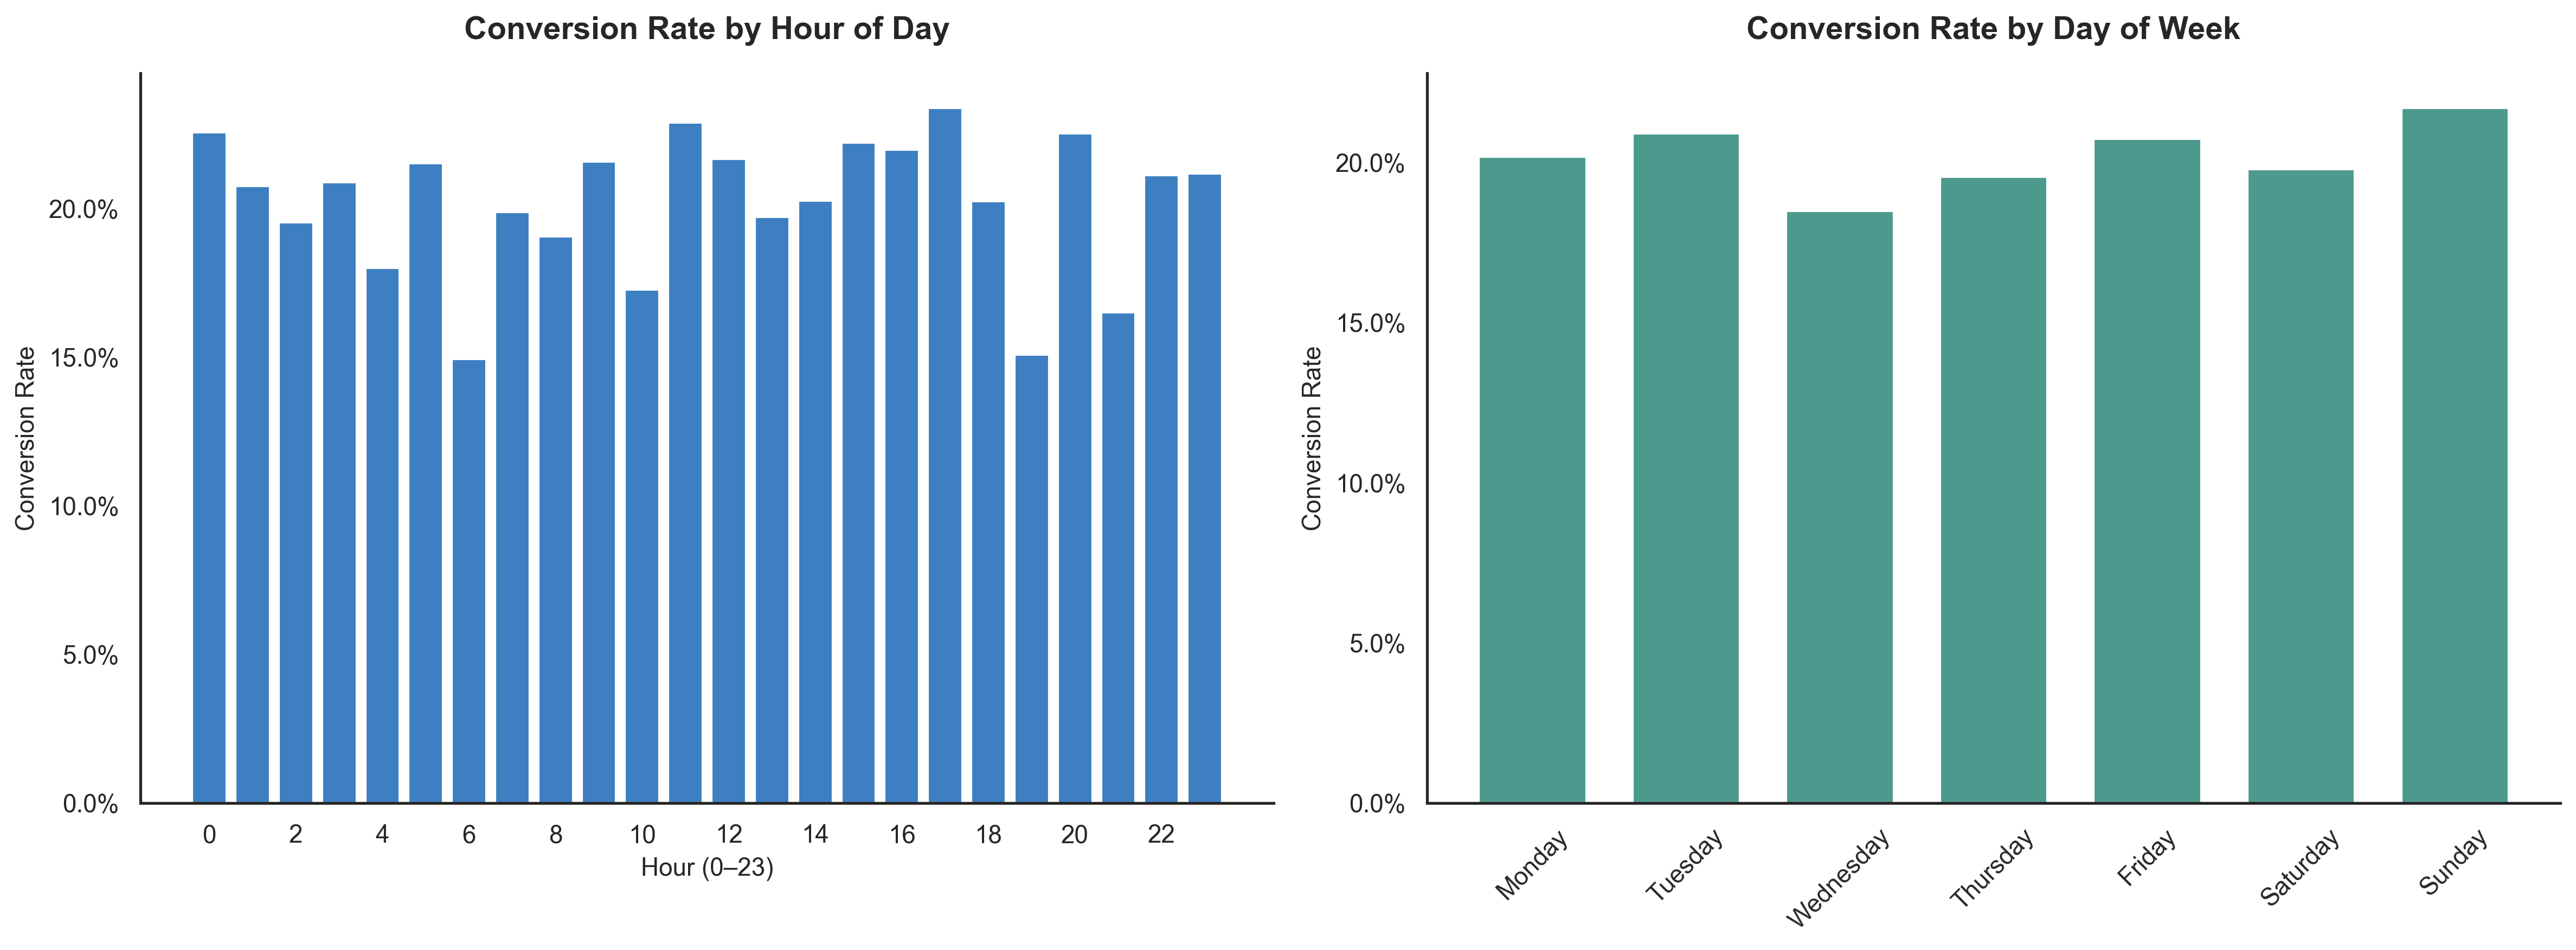

Conversion by Hour (Top 5):


,Hour,Purchased
17,17,23.39%
11,11,22.90%
0,0,22.57%
20,20,22.54%
15,15,22.22%



Conversion by Day:


,Day,Purchased
0,Monday,20.19%
1,Tuesday,20.91%
2,Wednesday,18.50%
3,Thursday,19.57%
4,Friday,20.76%
5,Saturday,19.81%
6,Sunday,21.72%


In [25]:
# Time-Based Conversion Analysis

# 1. Conversion by Hour of Day
session_hour = df.groupby('SessionID').agg(
    Hour=('HourOfDay', 'first'),
    Purchased=('Purchased', 'max')
).reset_index()

hour_conv = session_hour.groupby('Hour')['Purchased'].mean().reset_index()

# 2. Conversion by Day of Week
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

session_day = df.groupby('SessionID').agg(
    Day=('DayOfWeek', 'first'),
    Purchased=('Purchased', 'max')
).reset_index()

day_conv = (
    session_day.groupby('Day')['Purchased']
    .mean()
    .reindex(range(7))
    .reset_index()
)

day_conv['Day'] = day_order

# --- Plotting ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6), dpi=300)

# Hour chart
axes[0].bar(hour_conv['Hour'], hour_conv['Purchased'], color='#3D7FC1', width=0.8)
axes[0].set_title('Conversion Rate by Hour of Day', fontsize=14, fontweight='bold', pad=15)
axes[0].set_xlabel('Hour (0–23)', fontsize=11)
axes[0].set_ylabel('Conversion Rate', fontsize=11)
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[0].set_xticks(range(0, 24, 2))
sns.despine(ax=axes[0])

# Day chart
axes[1].bar(day_conv['Day'], day_conv['Purchased'], color='#4C9A8E', width=0.7)
axes[1].set_title('Conversion Rate by Day of Week', fontsize=14, fontweight='bold', pad=15)
axes[1].set_xlabel('')
axes[1].set_ylabel('Conversion Rate', fontsize=11)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[1].tick_params(axis='x', rotation=45)
sns.despine(ax=axes[1])

plt.tight_layout()
fig.savefig('08_time_based_conversion.png', dpi=300, bbox_inches='tight')
plt.show()

# Print summary
print("Conversion by Hour (Top 5):")
display(hour_conv.sort_values('Purchased', ascending=False).head().style.format({'Purchased': '{:.2%}'}))

print("\nConversion by Day:")
display(day_conv.style.format({'Purchased': '{:.2%}'}))

In [26]:
# Country-wise funnel session counts

country_funnel = (
    df.groupby(['Country', 'PageType'])['SessionID']
      .nunique()
      .unstack()
      .reindex(columns=funnel_steps, fill_value=0)
)

# Convert each country's funnel into percentage of its Home sessions
country_funnel_conversion = (
    country_funnel.div(country_funnel['home'], axis=0) * 100
)

print("Country-wise Funnel Conversion:")
display(country_funnel_conversion.round(2))

Country-wise Funnel Conversion:


PageType,home,product_page,cart,checkout,confirmation
Country,,,,,
Australia,100.0,78.77,32.06,21.67,19.18
Canada,100.0,81.26,32.73,21.68,19.58
France,100.0,81.91,33.78,25.00,22.61
Germany,100.0,76.24,30.16,22.05,18.78
India,100.0,80.34,32.19,22.36,20.66
UK,100.0,79.30,30.85,21.24,19.62
USA,100.0,80.17,32.01,23.09,20.82


In [27]:
# Create session-level data
session_country = (
    df.groupby('SessionID')
      .agg(
          Country=('Country', 'first'),
          Purchased=('Purchased', 'max')
      )
      .reset_index()
)

# Contingency table
country_contingency = pd.crosstab(
    session_country['Country'],
    session_country['Purchased']
)

# Chi-square test
chi2, p_value, dof, expected = chi2_contingency(
    country_contingency
)

print("Chi-Square Test: Country vs Conversion")
print(f"Chi-Square Statistic: {chi2:.4f}")
print(f"P-Value: {p_value:.4f}")
print(f"Degrees of Freedom: {dof}")

if p_value < 0.05:
    print("Result: Significant association between country and conversion.")
else:
    print("Result: No statistically significant association between country and conversion.")

Chi-Square Test: Country vs Conversion
Chi-Square Statistic: 4.6090
P-Value: 0.5948
Degrees of Freedom: 6
Result: No statistically significant association between country and conversion.


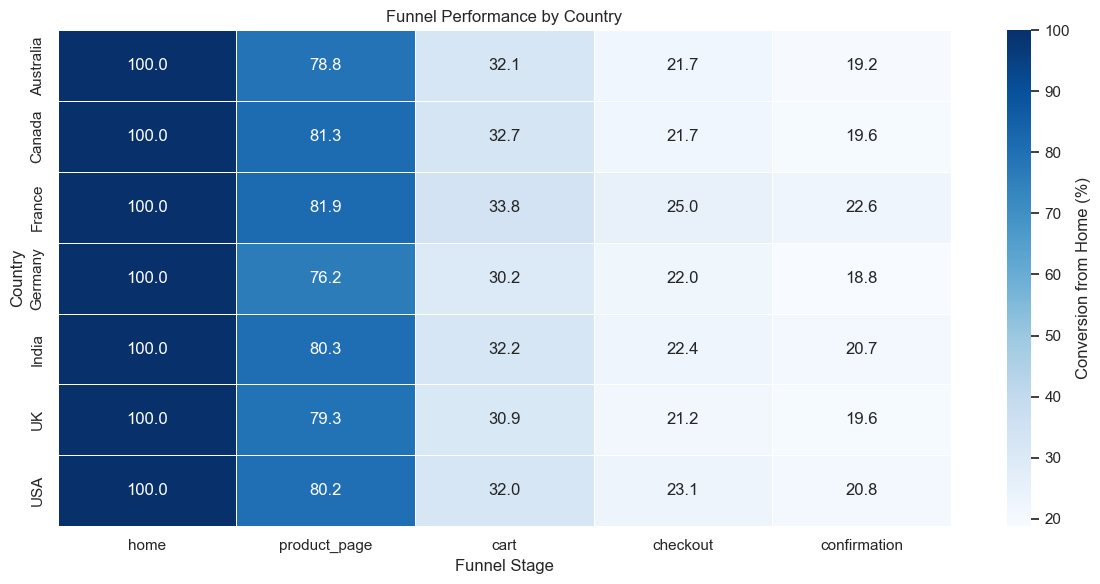

In [28]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    country_funnel_conversion,
    annot=True,
    fmt='.1f',
    cmap='Blues',
    linewidths=0.5,
    cbar_kws={'label': 'Conversion from Home (%)'}
)

plt.title('Funnel Performance by Country')
plt.xlabel('Funnel Stage')
plt.ylabel('Country')

plt.tight_layout()
plt.show()

## Product Page → Cart by Segment

In [29]:
def product_to_cart_analysis(segment):

    segment_funnel = (
        df.groupby([segment, 'PageType'])['SessionID']
          .nunique()
          .unstack()
          .reindex(columns=funnel_steps, fill_value=0)
    )

    segment_funnel['Product_to_Cart_%'] = (
        segment_funnel['cart'] /
        segment_funnel['product_page']
    ) * 100

    return segment_funnel[
        ['product_page', 'cart', 'Product_to_Cart_%']
    ].sort_values('Product_to_Cart_%')

print("Product → Cart by Device")
display(
    product_to_cart_analysis('DeviceType').round(2)
)

print("\nProduct → Cart by Referral Source")
display(
    product_to_cart_analysis('ReferralSource').round(2)
)

print("\nProduct → Cart by Country")
display(
    product_to_cart_analysis('Country').round(2)
)

Product → Cart by Device


PageType,product_page,cart,Product_to_Cart_%
DeviceType,,,
Mobile,1342,537,40.01
Desktop,1321,529,40.05
Tablet,1324,533,40.26



Product → Cart by Referral Source


PageType,product_page,cart,Product_to_Cart_%
ReferralSource,,,
Social Media,987,378,38.30
Direct,966,386,39.96
Email,1020,408,40.00
Google,1014,427,42.11



Product → Cart by Country


PageType,product_page,cart,Product_to_Cart_%
Country,,,
UK,586,228,38.91
Germany,536,212,39.55
USA,566,226,39.93
India,564,226,40.07
Canada,581,234,40.28
Australia,538,219,40.71
France,616,254,41.23


In [30]:
# Sessions that reached Product Page
product_sessions = set(
    df.loc[df['PageType'] == 'product_page', 'SessionID']
)

cart_sessions = set(
    df.loc[df['PageType'] == 'cart', 'SessionID']
)

product_users = (
    df[df['SessionID'].isin(product_sessions)]
    .groupby('SessionID')
    .agg(
        DeviceType=('DeviceType', 'first'),
        ReferralSource=('ReferralSource', 'first'),
        Country=('Country', 'first')
    )
    .reset_index()
)

product_users['ReachedCart'] = (
    product_users['SessionID'].isin(cart_sessions)
).astype(int)

In [31]:
for attribute in ['DeviceType', 'ReferralSource', 'Country']:

    contingency = pd.crosstab(
        product_users[attribute],
        product_users['ReachedCart']
    )

    chi2, p_value, dof, expected = chi2_contingency(
        contingency
    )

    print(f"\n{attribute} vs Product → Cart")
    print(f"Chi-Square: {chi2:.4f}")
    print(f"P-Value: {p_value:.4f}")
    print(f"Degrees of Freedom: {dof}")


DeviceType vs Product → Cart
Chi-Square: 0.0192
P-Value: 0.9905
Degrees of Freedom: 2

ReferralSource vs Product → Cart
Chi-Square: 3.0529
P-Value: 0.3835
Degrees of Freedom: 3

Country vs Product → Cart
Chi-Square: 0.8401
P-Value: 0.9910
Degrees of Freedom: 6


In [32]:
# Sessions that reached the cart
cart_sessions = set(
    df.loc[df['PageType'] == 'cart', 'SessionID']
)

# Session-level data
session_cart = (
    df[df['SessionID'].isin(cart_sessions)]
    .groupby('SessionID')
    .agg(
        DeviceType=('DeviceType', 'first'),
        ReferralSource=('ReferralSource', 'first'),
        Country=('Country', 'first'),
        Purchased=('Purchased', 'max')
    )
    .reset_index()
)

# 1 = abandoned, 0 = completed purchase
session_cart['CartAbandoned'] = (
    session_cart['Purchased'] == 0
).astype(int)

# Device-level abandonment
device_abandonment = (
    session_cart.groupby('DeviceType')
    .agg(
        CartSessions=('SessionID', 'count'),
        AbandonedSessions=('CartAbandoned', 'sum'),
        AbandonmentRate=('CartAbandoned', 'mean')
    )
    .reset_index()
)

device_abandonment['Abandonment_%'] = (
    device_abandonment['AbandonmentRate'] * 100
)

display(
    device_abandonment[
        ['DeviceType', 'CartSessions',
         'AbandonedSessions', 'Abandonment_%']
    ].round(2)
)

,DeviceType,CartSessions,AbandonedSessions,Abandonment_%
0,Desktop,529,190,35.92
1,Mobile,537,200,37.24
2,Tablet,533,199,37.34


In [33]:
contingency = pd.crosstab(
    session_cart['DeviceType'],
    session_cart['CartAbandoned']
)

chi2, p_value, dof, expected = chi2_contingency(
    contingency
)

print("Chi-Square Test: Device vs Cart Abandonment")
print(f"Chi-Square Statistic: {chi2:.4f}")
print(f"P-Value: {p_value:.4f}")
print(f"Degrees of Freedom: {dof}")

if p_value < 0.05:
    print("Result: Significant association.")
else:
    print("Result: No statistically significant association.")

Chi-Square Test: Device vs Cart Abandonment
Chi-Square Statistic: 0.2877
P-Value: 0.8660
Degrees of Freedom: 2
Result: No statistically significant association.


## One-Time vs Returning Visitors

Dataset have:

1,872 unique users
5,000 sessions

So users can have multiple sessions.

Are returning visitors more likely to convert than users visiting for the first time?

In [34]:
# Create session-level data from the original dataframe
session = (
    df.groupby('SessionID')
      .agg(
          UserID=('UserID', 'first'),
          Purchased=('Purchased', 'max')
      )
      .reset_index()
)

# Count how many sessions each user has
user_behavior = (
    session.groupby('UserID')
    .agg(
        SessionCount=('SessionID', 'nunique'),
        PurchasedSessions=('Purchased', 'sum')
    )
    .reset_index()
)

# Classify users
user_behavior['UserType'] = np.where(
    user_behavior['SessionCount'] == 1,
    'One-time Visitor',
    'Returning Visitor'
)

# Check whether user converted at least once
user_behavior['UserConverted'] = (
    user_behavior['PurchasedSessions'] > 0
).astype(int)

# Calculate conversion by visitor type
user_conversion = (
    user_behavior.groupby('UserType')
    .agg(
        Users=('UserID', 'count'),
        ConvertedUsers=('UserConverted', 'sum'),
        ConversionRate=('UserConverted', 'mean')
    )
    .reset_index()
)

user_conversion['Conversion_%'] = (
    user_conversion['ConversionRate'] * 100
)

display(user_conversion.round(2))

,UserType,Users,ConvertedUsers,ConversionRate,Conversion_%
0,One-time Visitor,439,85,0.19,19.36
1,Returning Visitor,1433,707,0.49,49.34


In [35]:
contingency = pd.crosstab(
    user_behavior['UserType'],
    user_behavior['UserConverted']
)

display(contingency)

chi2, p_value, dof, expected = chi2_contingency(contingency)

print(f"Chi-square statistic: {chi2:.4f}")
print(f"p-value: {p_value:.10f}")
print(f"Degrees of freedom: {dof}")

alpha = 0.05

if p_value < alpha:
    print(
        "There is a statistically significant association between "
        "visitor type and conversion."
    )
else:
    print(
        "There is no statistically significant association between "
        "visitor type and conversion."
    )

UserConverted,0,1
UserType,,
One-time Visitor,354,85
Returning Visitor,726,707


Chi-square statistic: 122.4785
p-value: 0.0000000000
Degrees of freedom: 1
There is a statistically significant association between visitor type and conversion.


This analysis compares one-time visitors with returning visitors to determine whether visitor type is associated with user-level conversion.

A user with only one session is classified as a One-time Visitor, while a user with more than one session is classified as a Returning Visitor. A user is considered converted if they completed a purchase in at least one of their sessions.

The analysis shows that one-time visitors had a conversion rate of approximately 19.36%, while returning visitors had a conversion rate of approximately 49.34%.

A Chi-square test of independence was used to test the relationship between visitor type and conversion. The resulting p-value was approximately 1.81 × 10⁻²⁸, which is below the 0.05 significance level. Therefore, there is a statistically significant association between visitor type and user-level conversion in this dataset.

This result indicates that returning visitors were substantially more likely to have converted at least once than one-time visitors. However, this is an association and does not establish that returning to the website itself caused the higher conversion rate.

## Time-Based Conversion Check  

Checked if hour of day or day of week affects conversion. Hourly rates range between 20–23%, and daily rates between 18–22%. No meaningful pattern — time of visit doesn't matter here. Again, real data would likely show more variation.


### Core Problem  

The biggest loss in the funnel happens between **Product Page → Cart**, where nearly **60% of users drop off**.

This is the single most critical issue affecting overall conversion.


### What is NOT the Problem  

- Device type is not a major factor — all devices show similar funnel patterns — no difference (p-value 0.98)  
- Referral source has only a minor impact — conversion differences are small across channels — no difference (p-value 0.47)
- Time of visit — no pattern
- Users are not leaving quickly — time spent on product pages is similar for buyers and non-buyers  


### Real Issue  

Users are **engaging with the product page but not taking action**.

- Users spend ~95–98 seconds on product pages  
- But many do not add items to the cart  
- Sessions with **0 items in cart never convert**  

This shows the problem is not attention, but **lack of conversion after engagement**


### Key Behavioral Insight  

The most important action is adding the **first item to the cart**

- Once a user adds 1 item → conversion jumps to ~35–38%  
- Adding more items does not significantly increase conversion  

This means the funnel depends heavily on triggering the **first commitment action**


### Cart & Checkout  

- Users who reach checkout convert at a very high rate (~90%)  
- Cart abandonment exists but is evenly distributed across devices  

This confirms that the checkout process is relatively strong


### What Should Be Fixed  

Focus should be on improving the **Product Page → Cart transition**

Key improvements:

- Make “Add to Cart” more visible and easier to use  
- Improve product clarity (images, benefits, descriptions)  
- Highlight pricing and value clearly  
- Add trust signals (reviews, ratings, guarantees)  


### Business Impact  

Improving the Product Page conversion even slightly can lead to a major increase in overall sales, because this is where most users are lost. Small gains at this step will have the highest impact on revenue.
